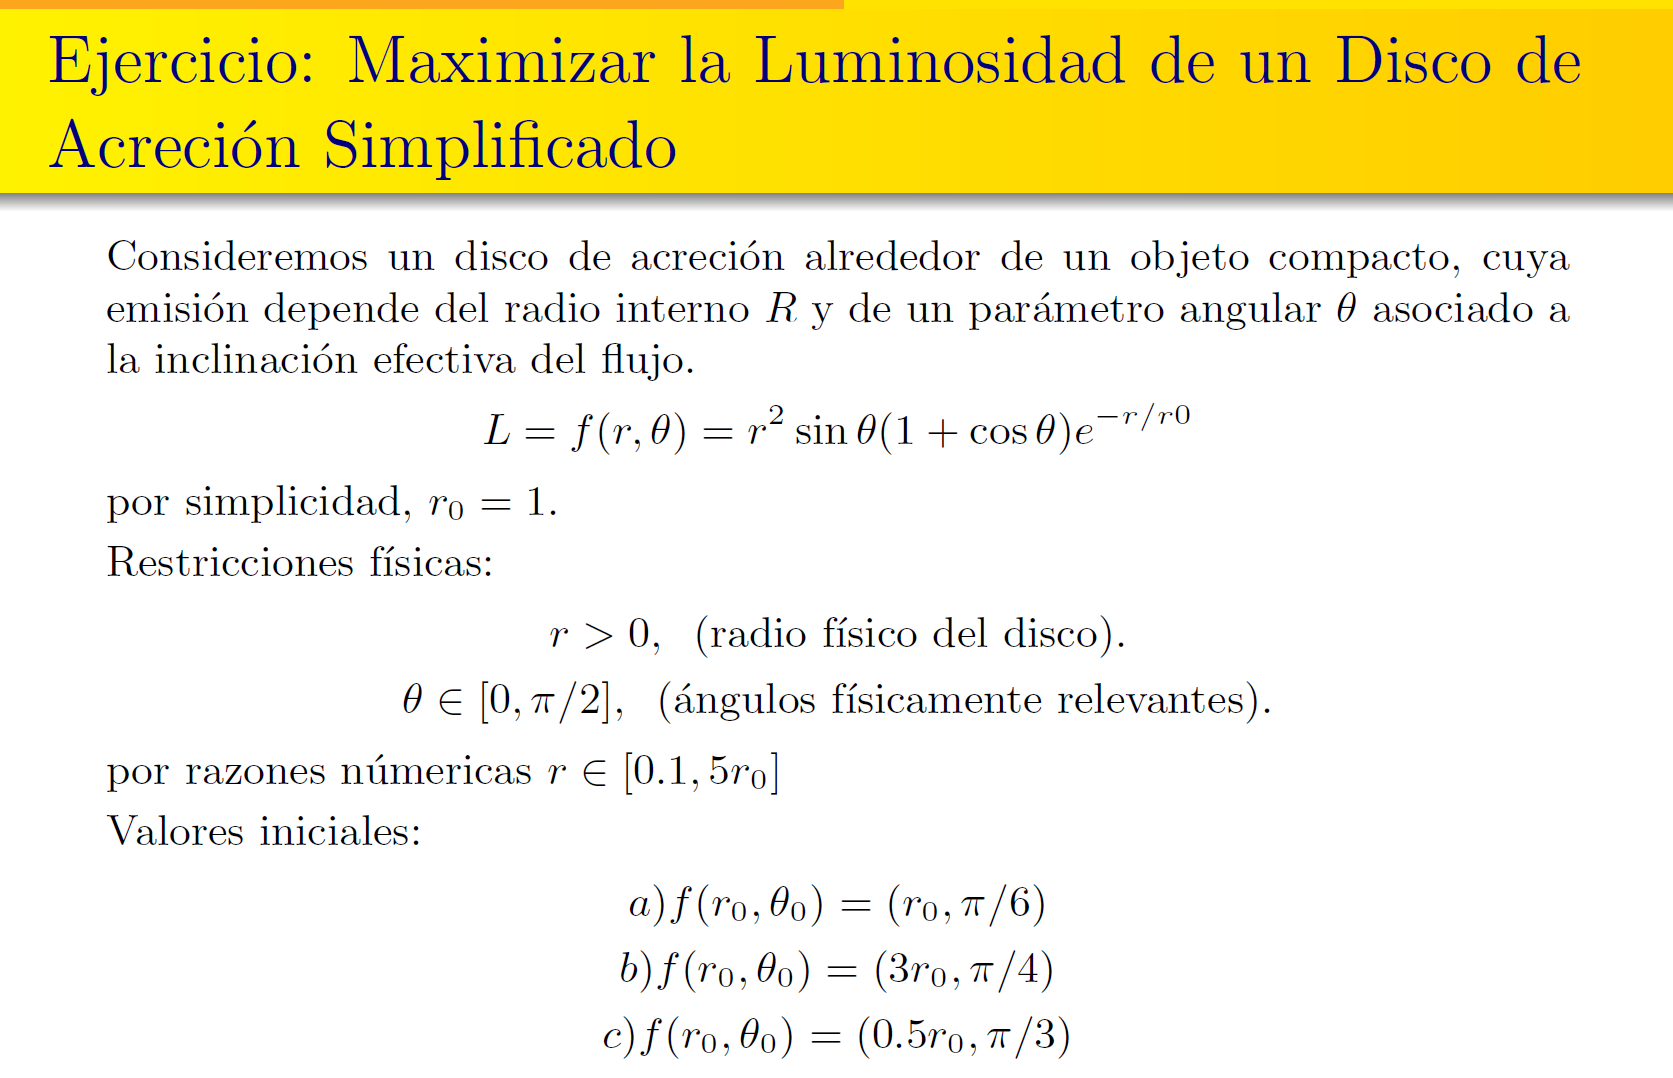

In [4]:
import numpy as np

# Parámetros físicos y función de Luminosidad

r0 = 1
r_min, r_max = 0.1, 5.0
theta_min, theta_max = 0.0, np.pi / 2

def luminosidad(r, theta):
    return (r**2) * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-r / r0)

def grad_r(r, theta):
    return (2 * r - r**2) * np.exp(-r / r0) * np.sin(theta) * (1 + np.cos(theta))

def grad_theta(r, theta):
    return (r**2) * np.exp(-r / r0) * (np.cos(theta) + np.cos(2 * theta))

In [2]:
# Algoritmo del Gradiente

def metodo_gradiente(r_inicial, theta_inicial, tasa_aprendizaje=0.2, tolerancia=1e-6, max_iter=100):
    r = r_inicial
    theta = theta_inicial
    
    print(f"Punto inicial: r = {r:.4f}, theta = {theta:.4f} rad")
    print(f"Luminosidad inicial: {luminosidad(r, theta):.6f}\n")
    
    for iteracion in range(max_iter):
        dL_dr = grad_r(r, theta)
        dL_dtheta = grad_theta(r, theta)
        
        r_anterior = r
        theta_anterior = theta
        
        # Actualización por gradiente ascendente
        r = r + tasa_aprendizaje * dL_dr
        theta = theta + tasa_aprendizaje * dL_dtheta
        
        # Restricciones físicas
        r = np.clip(r, r_min, r_max)
        theta = np.clip(theta, theta_min, theta_max)
        
        cambio_r = abs(r - r_anterior)
        cambio_theta = abs(theta - theta_anterior)
        
        if cambio_r < tolerancia and cambio_theta < tolerancia:
            print(f"Convergencia en iteración {iteracion}.")
            break
            
    print(f"Radio óptimo r = {r:.6f}")
    print(f"Ángulo óptimo theta = {theta:.6f} rad ({np.degrees(theta):.2f}°)")
    print(f"Luminosidad máxima L = {luminosidad(r, theta):.6f}\n")
    
    return r, theta

In [6]:
# Punto A, Punto B y Punto C

print("Punto A")
metodo_gradiente(1.0, np.pi/6)

print("Punto B")
metodo_gradiente(3.0, np.pi/4)

print("Punto C")
metodo_gradiente(0.5, np.pi/3)

Punto A
Punto inicial: r = 1.0000, theta = 0.5236 rad
Luminosidad inicial: 0.343236

Radio óptimo r = 1.999521
Ángulo óptimo theta = 1.047198 rad (60.00°)
Luminosidad máxima L = 0.703223

Punto B
Punto inicial: r = 3.0000, theta = 0.7854 rad
Luminosidad inicial: 0.540885

Radio óptimo r = 2.001374
Ángulo óptimo theta = 1.047198 rad (60.00°)
Luminosidad máxima L = 0.703222

Punto C
Punto inicial: r = 0.5000, theta = 1.0472 rad
Luminosidad inicial: 0.196977

Radio óptimo r = 1.999377
Ángulo óptimo theta = 1.047198 rad (60.00°)
Luminosidad máxima L = 0.703223



(np.float64(1.9993770562260242), np.float64(1.0471975511965976))